In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sr = 200
data = pd.read_csv('17Hz_contrast_smooth.csv')
bp_low = 3
bp_high = 37
eeg_channels = ['Channel_1', 'Channel_2', 'Channel_3', 'Channel_4']
eeg_data = data[eeg_channels].values  # Shape: (n_samples, 4)
timestamps = range(len(eeg_data))  # Assuming timestamps are sequential integers

In [9]:
from scipy.signal import butter, filtfilt, iirnotch

# ganglion sr is 200 Hz
sr = 200

def bandpass_filter(data, lowcut, highcut, fs):
    nyquist = fs / 2
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(6, [low, high], btype='band')
    return filtfilt(b, a, data, axis=0)

def notch_filter(data, freq, fs):
    nyquist = fs / 2
    b, a = iirnotch(freq / nyquist, 30)
    return filtfilt(b, a, data, axis=0)

eeg_filtered = bandpass_filter(eeg_data, bp_low, bp_high, sr)
eeg_filtered = notch_filter(eeg_data, 50, sr)
print(eeg_filtered.shape)

(8042, 4)


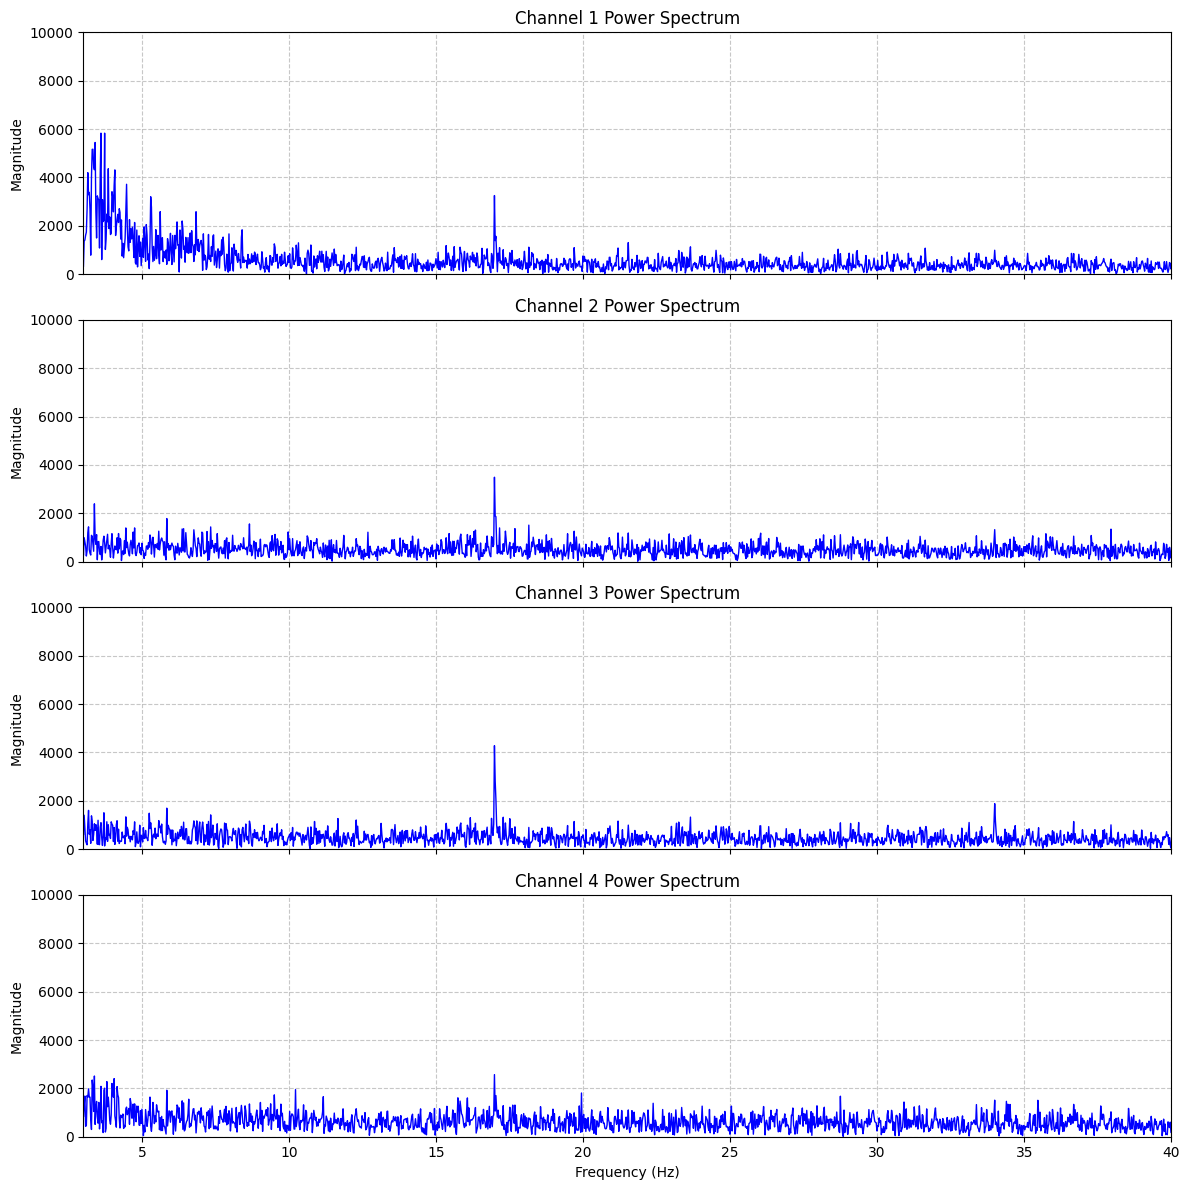

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq

# 1. Define signal parameters
sr = 200  # Sampling rate in Hz
n_samples = eeg_filtered.shape[0]
n_channels = eeg_filtered.shape[1]

# 2. Generate the frequency axis
# fftfreq returns both positive and negative frequencies
freqs = fftfreq(n_samples, 1/sr)

# We only need the positive half of the spectrum for plotting
pos_freqs = freqs[:n_samples//2]

# 3. Set up the plotting grid (4 rows, 1 column)
fig, axes = plt.subplots(n_channels, 1, figsize=(12, 12), sharex=True)

# 4. Loop through each channel, compute FFT, and plot
for ch in range(n_channels):
    # Extract the 1D array and remove any residual DC offset (mean centering)
    channel_data = eeg_filtered[:, ch]
    channel_data = channel_data - np.mean(channel_data)
    
    # Compute the 1D Discrete Fourier Transform
    fft_values = fft(channel_data)
    
    # Get the magnitude of the positive frequencies
    power_spectrum = np.abs(fft_values[:n_samples//2])
    
    # Plot from index 1 onward to explicitly drop the 0 Hz spike
    axes[ch].plot(pos_freqs[1:], power_spectrum[1:], color='b', linewidth=1)
    axes[ch].set_title(f'Channel {ch + 1} Power Spectrum')
    axes[ch].set_ylabel('Magnitude')
    axes[ch].grid(True, linestyle='--', alpha=0.7)
    axes[ch].set_xlim(3, 40)
    axes[ch].set_ylim(0, 10000)

# 5. Formatting
axes[-1].set_xlabel('Frequency (Hz)')

# Zoom in on the frequency band relevant to SSVEP (e.g., 0 to 50 Hz)
plt.tight_layout()
plt.show()

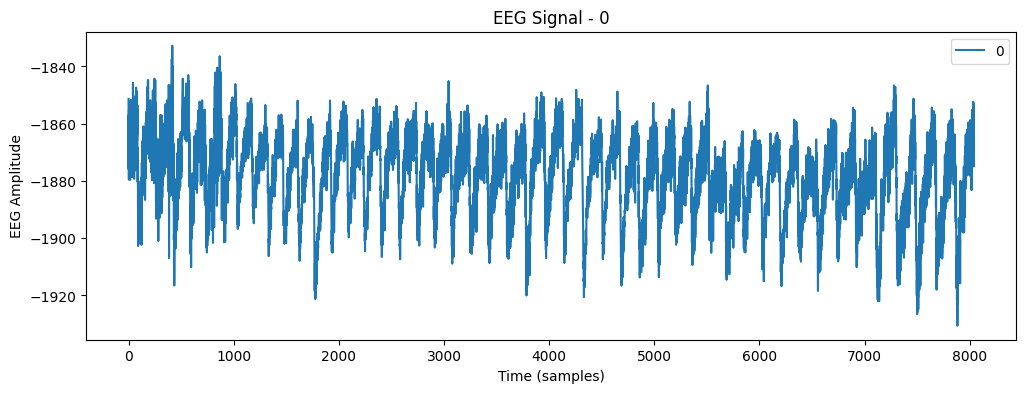

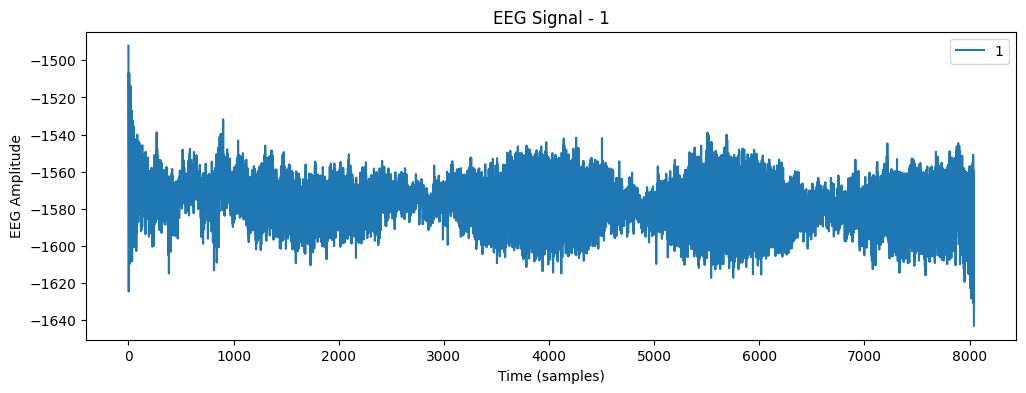

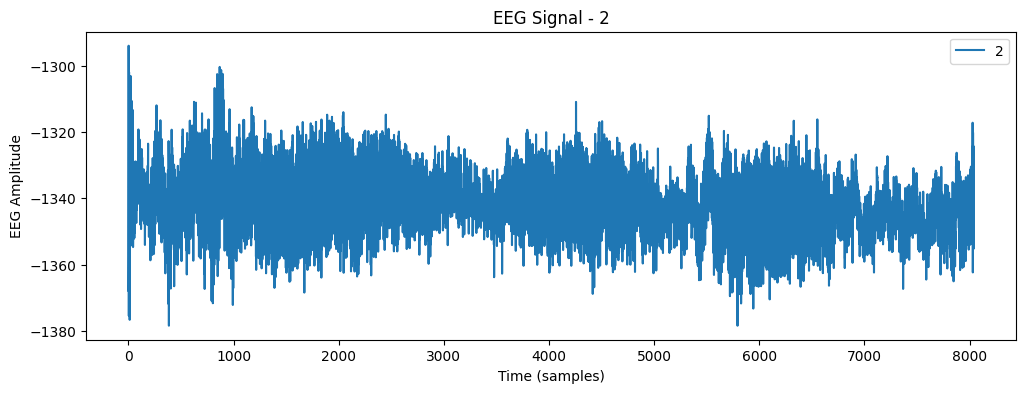

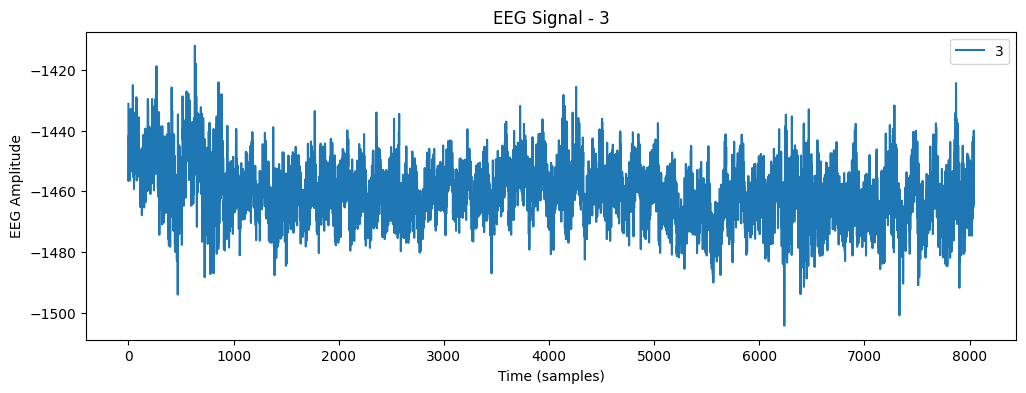

In [11]:
for channel in range(4):
    plt.figure(figsize=(12, 4))
    plt.plot(timestamps, eeg_filtered[:, channel], label=channel)
    plt.xlabel('Time (samples)')
    plt.ylabel('EEG Amplitude')
    plt.title(f'EEG Signal - {channel}')
    plt.legend()
    plt.show()


In [12]:
windows = []
window_size = 3 * sr  # seconds * 200 Hz
step_size = 2 * sr     # seconds * 200 Hz
    
# Added +1 to ensure the final window is captured if it fits perfectly
for start in range(0, len(eeg_filtered) - window_size + 1, step_size):
    end = start + window_size
    window = eeg_filtered[start:end, :]
    windows.append(window)

print(f"Created {len(windows)} windows")
print(f"Each window shape: {windows[0].shape}")

Created 19 windows
Each window shape: (600, 4)


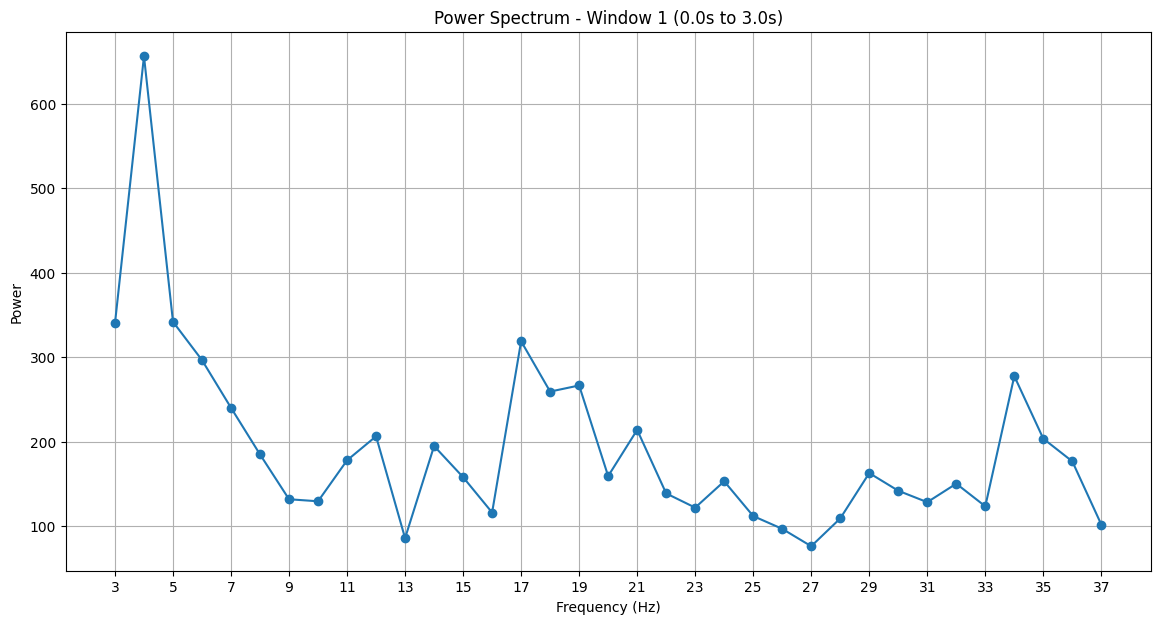

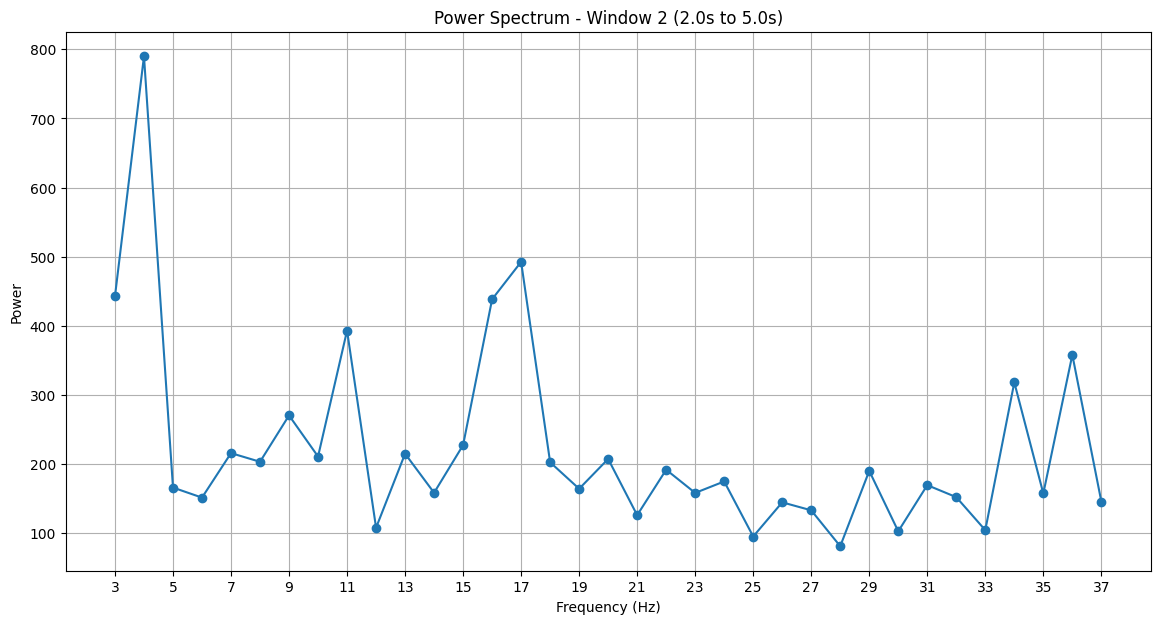

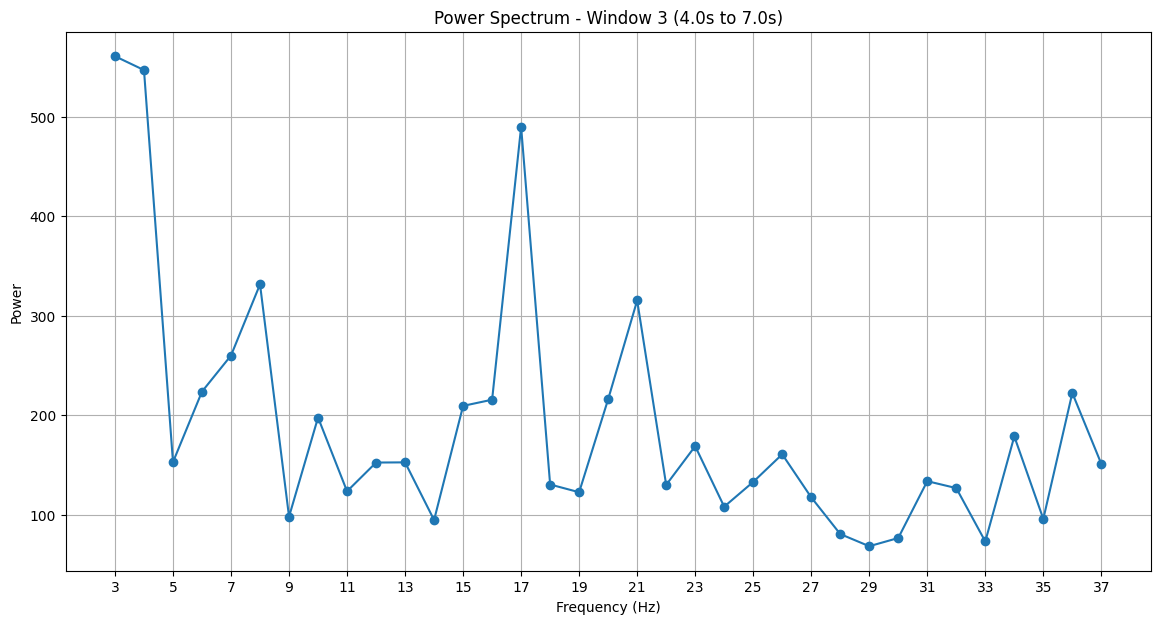

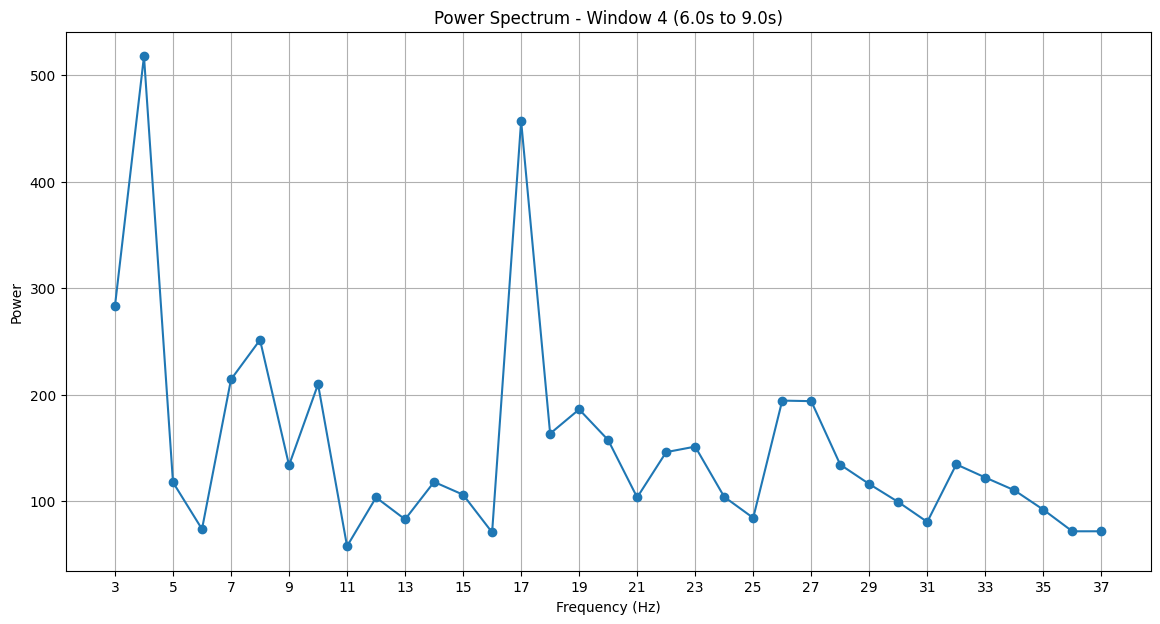

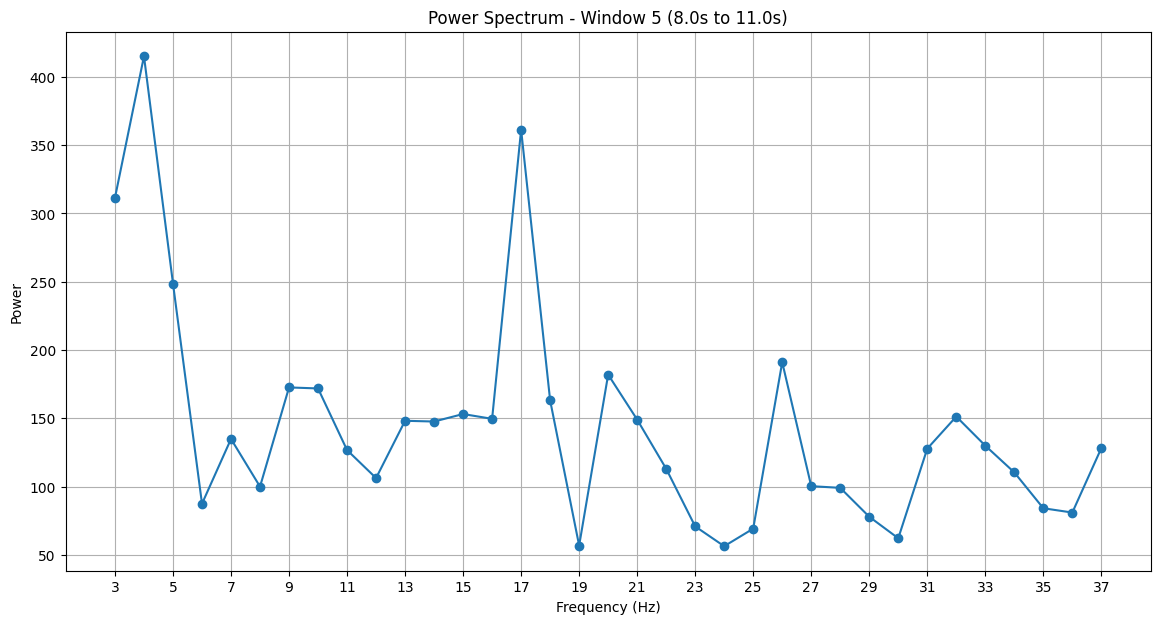

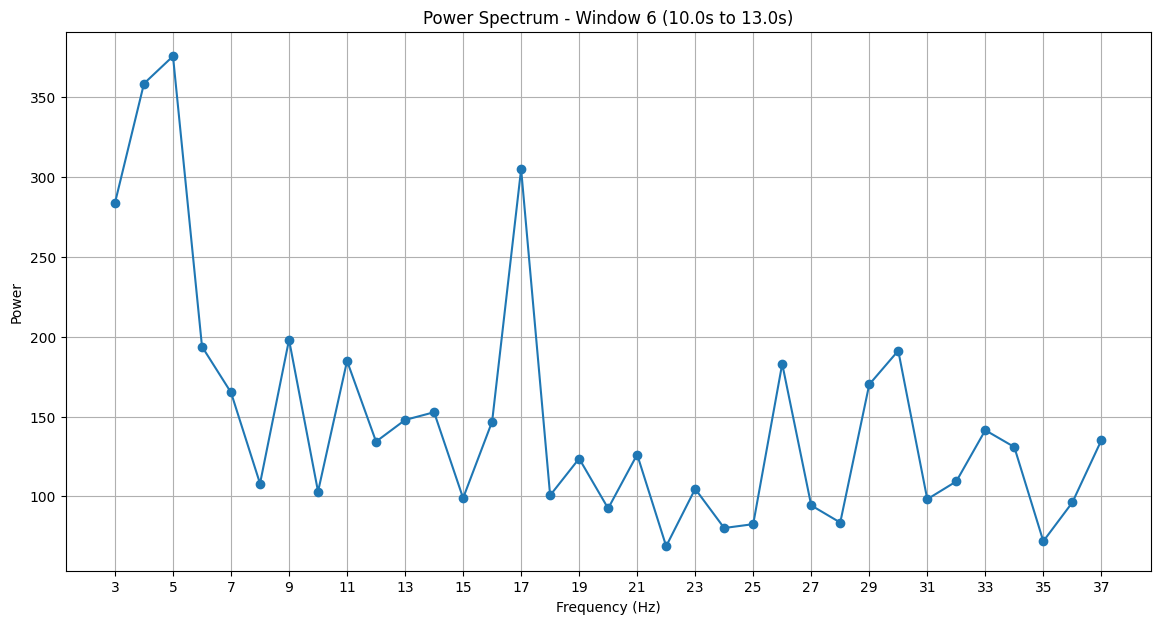

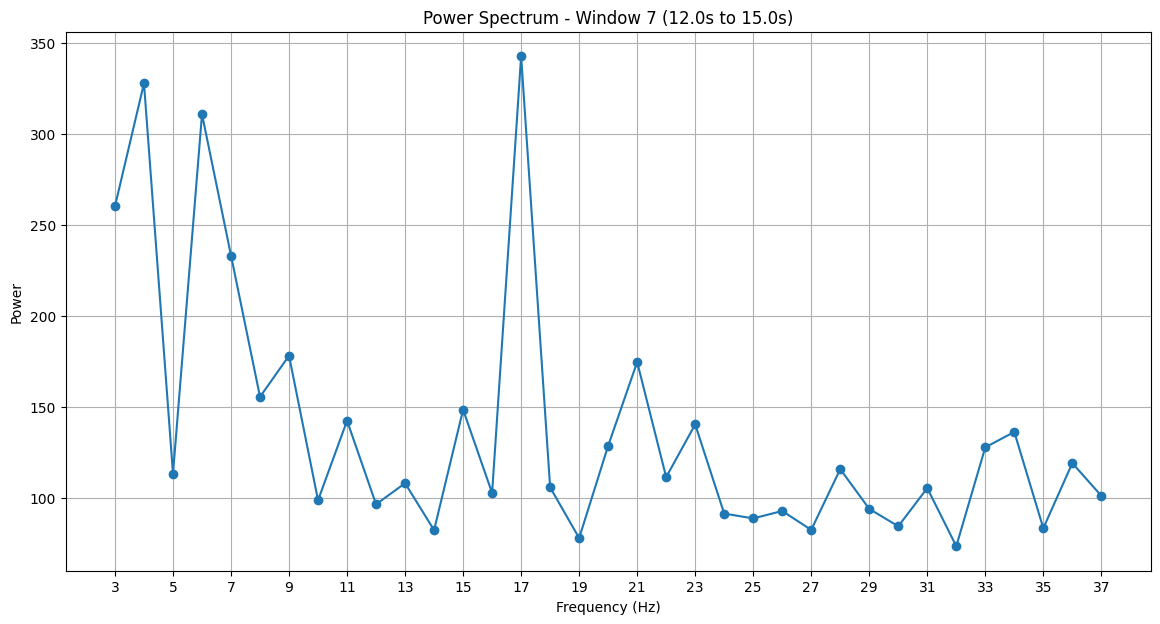

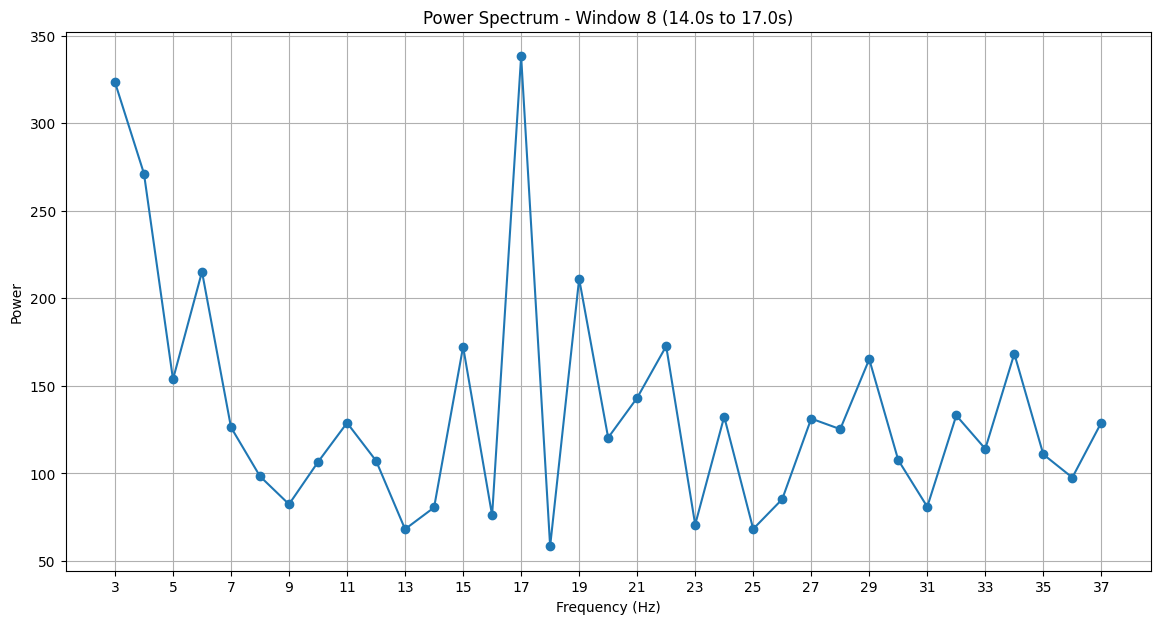

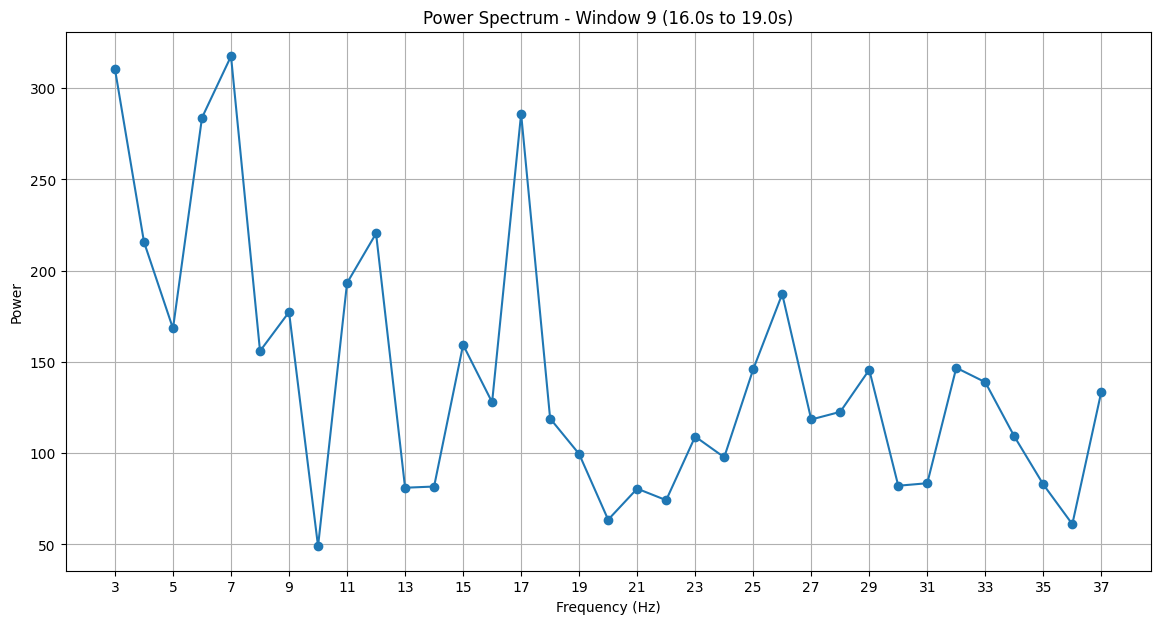

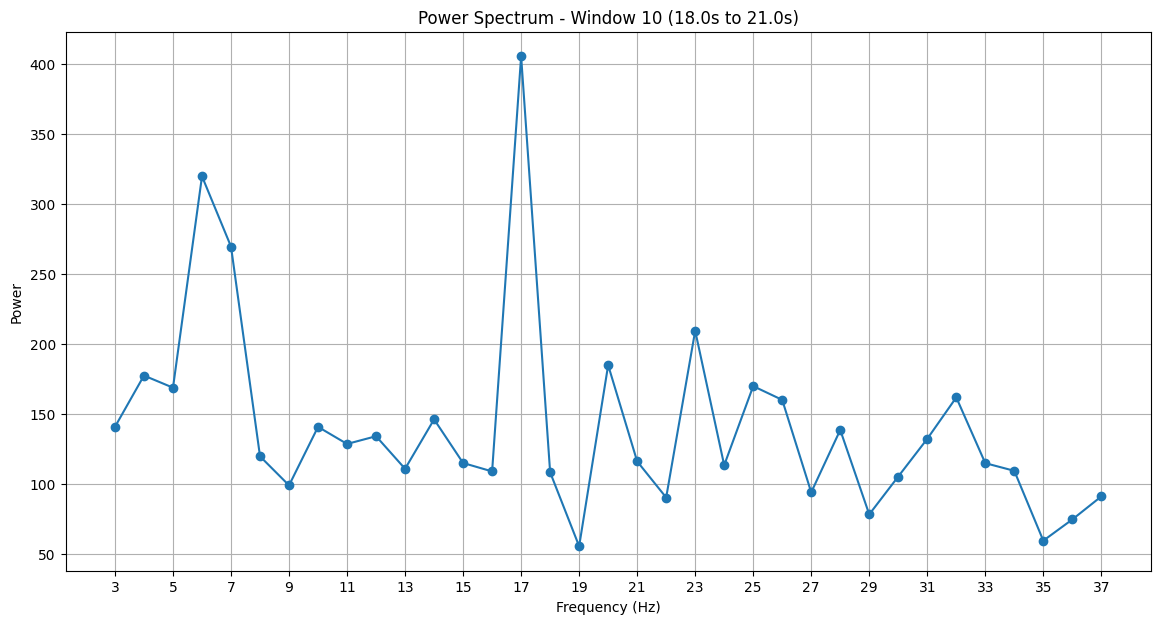

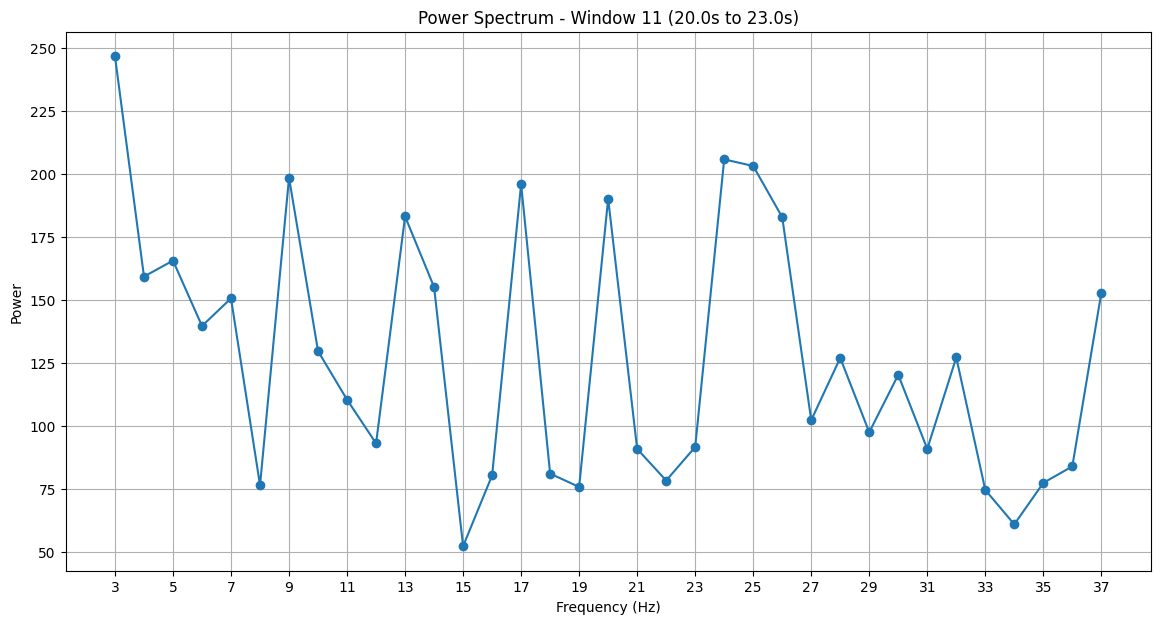

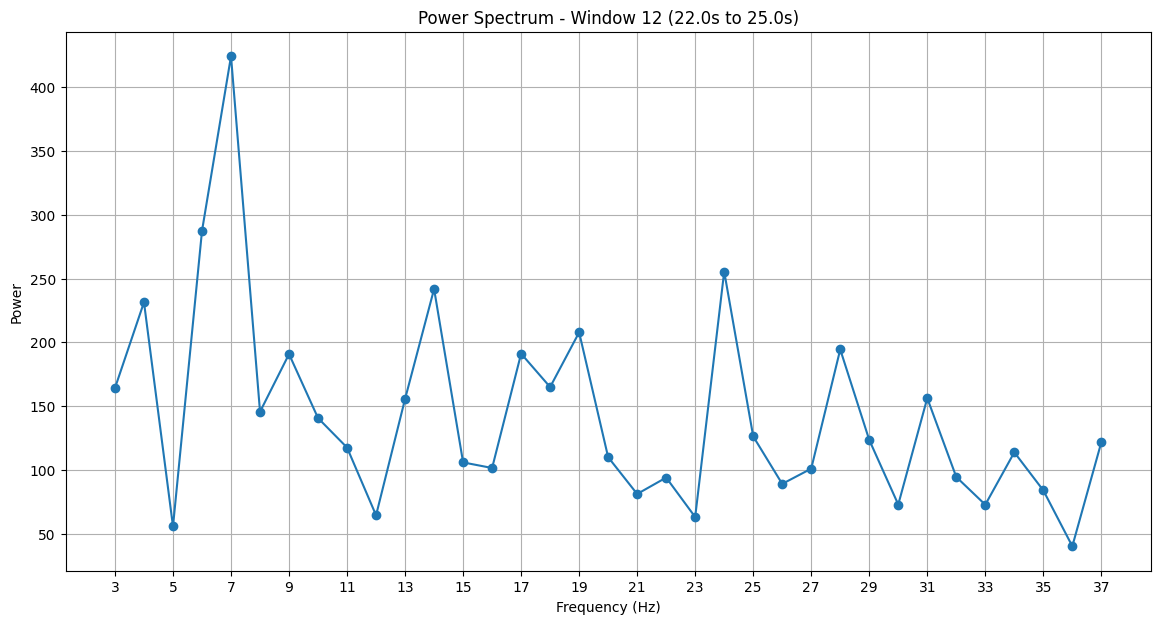

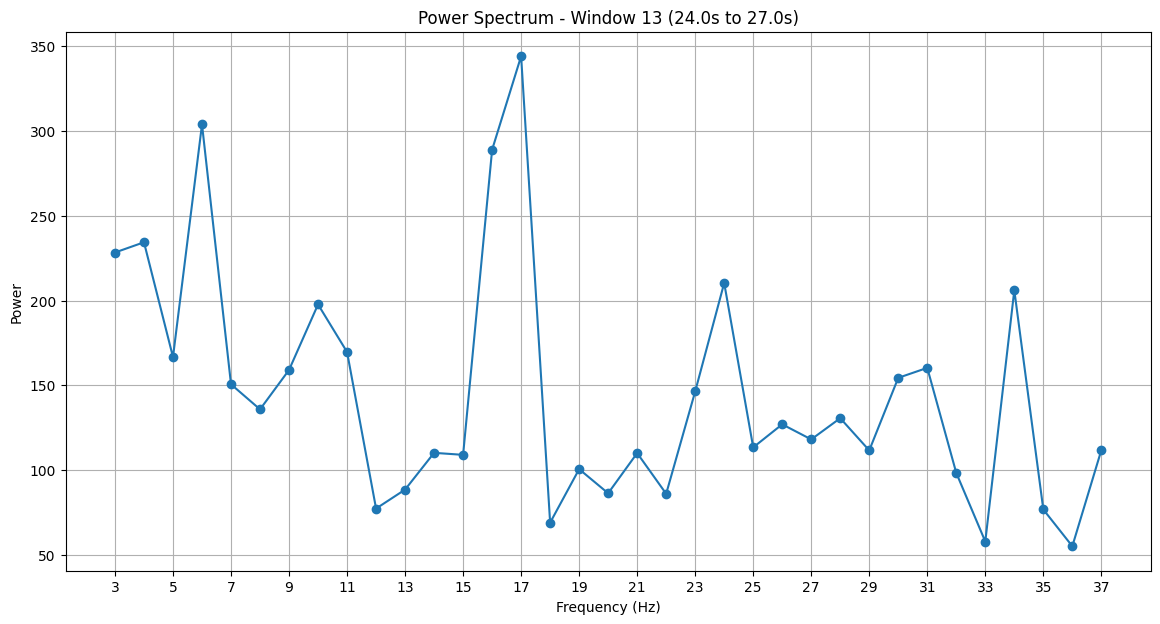

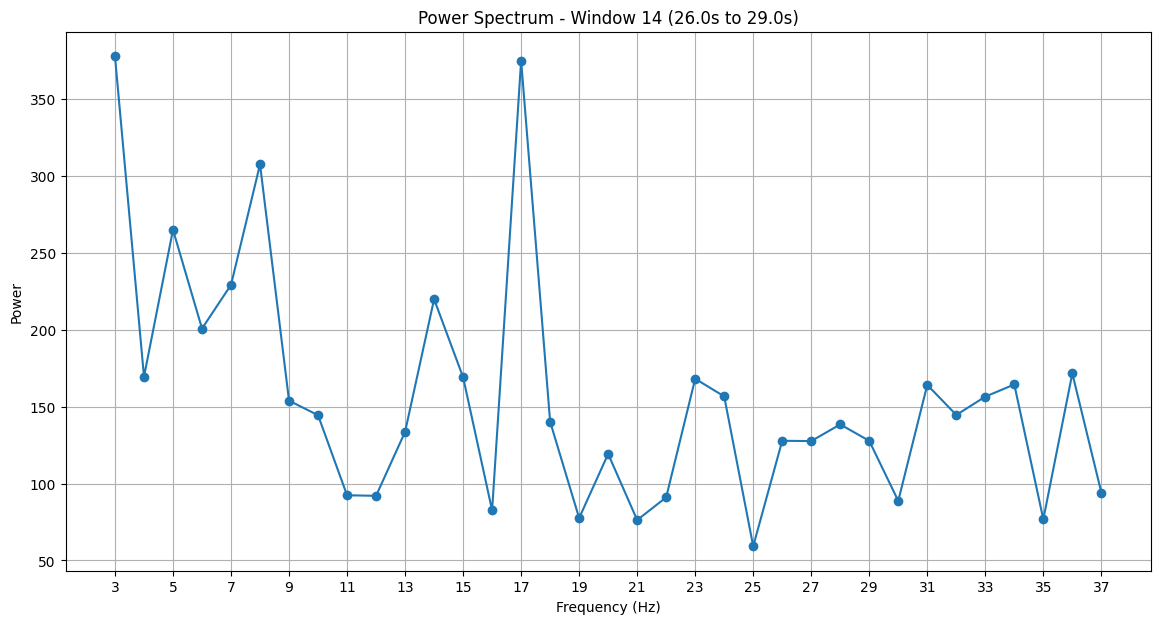

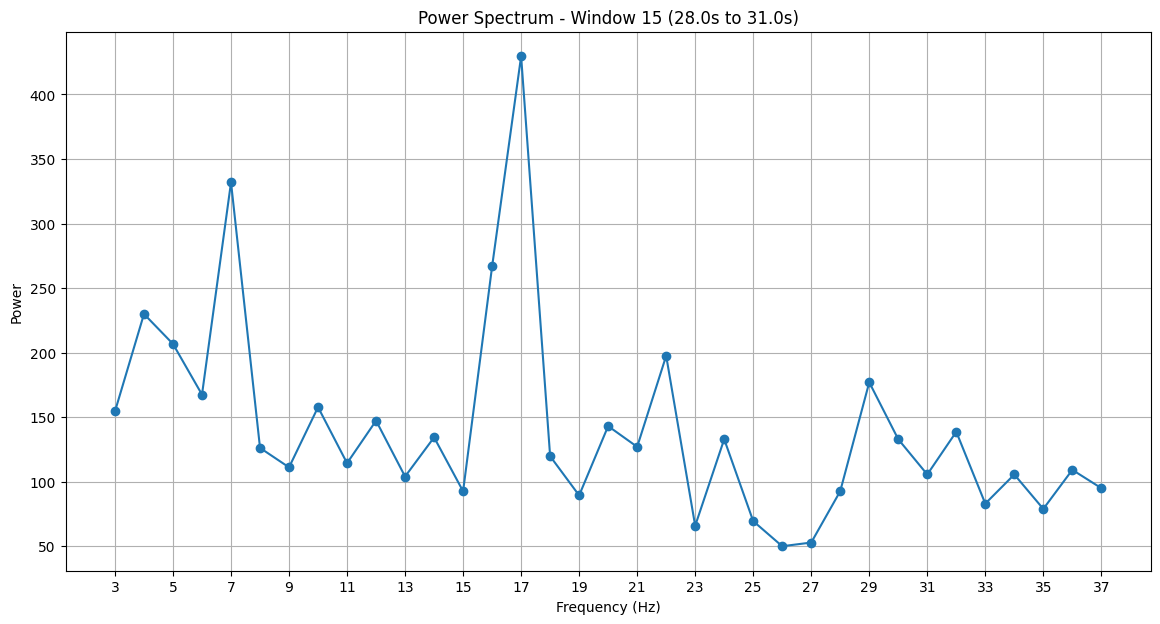

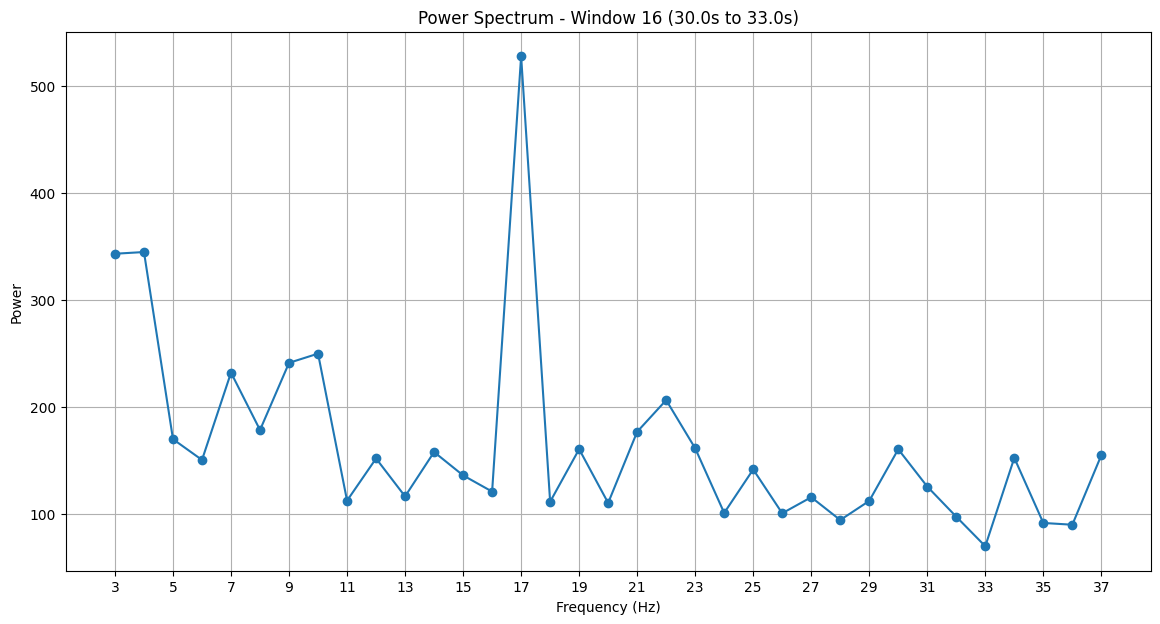

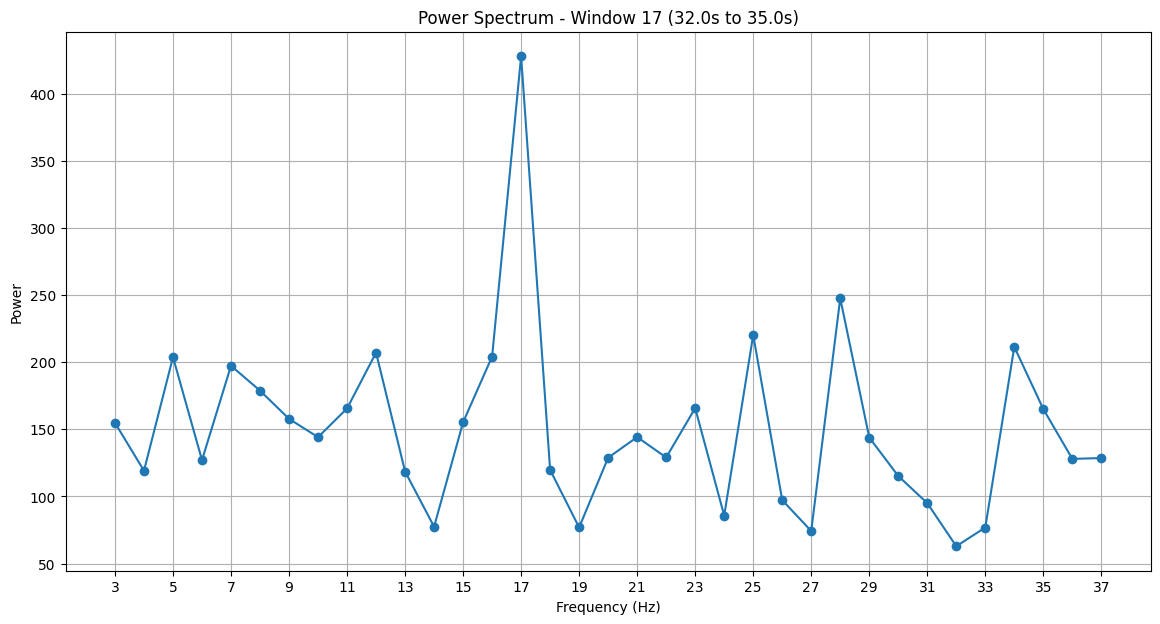

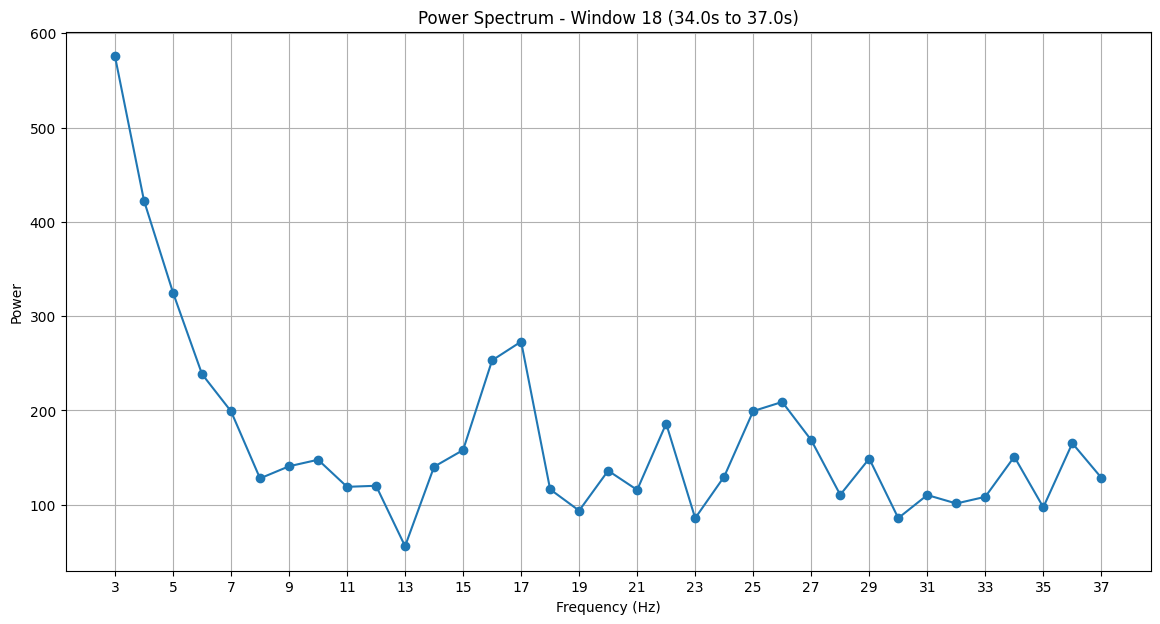

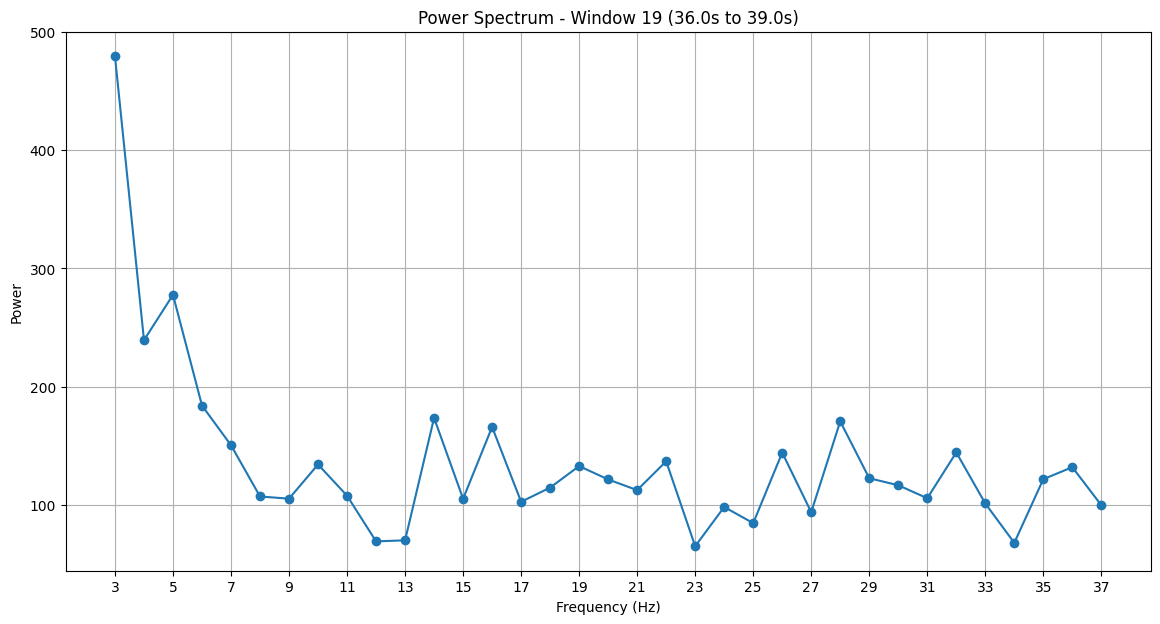

In [ ]:
from scipy.fft import fft, fftfreq
import numpy as np
import matplotlib.pyplot as plt

n_samples = windows[0].shape[0]
n_channels = windows[0].shape[1]

target_freqs = range(int(bp_low), int(bp_high) + 1)

# Process and plot each window separately
for i, window in enumerate(windows):
    # Store power for each frequency for the current window
    window_powers = {freq: [] for freq in target_freqs}
    
    # Compute FFT for each channel in this window
    for ch in range(n_channels):
        channel_data = window[:, ch]
        
        fft_values = fft(channel_data)
        fft_freqs = fftfreq(n_samples, 1/sr)
        
        power_spectrum = np.abs(fft_values[:n_samples//2])
        positive_freqs = fft_freqs[:n_samples//2]
        
        # Extract power at each target frequency
        for target_freq in target_freqs:
            idx = np.argmin(np.abs(positive_freqs - target_freq))
            window_powers[target_freq].append(power_spectrum[idx])

    # Average power across the 4 channels for this specific window
    avg_powers = [np.mean(window_powers[freq]) for freq in target_freqs]
    
    # Calculate time range for the title
    start_time = (i * step_size) / sr
    end_time = start_time + (window_size / sr)
    
    # Plot each window in a separate figure to keep it large and clear
    plt.figure(figsize=(14, 7))
    plt.plot(list(target_freqs), avg_powers, marker='o')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Power')
    plt.title(f'Power Spectrum - Window {i+1} ({start_time:.1f}s to {end_time:.1f}s)')
    plt.grid(True)
    plt.xticks(range(int(bp_low), int(bp_high) + 1, 2))
    plt.show()

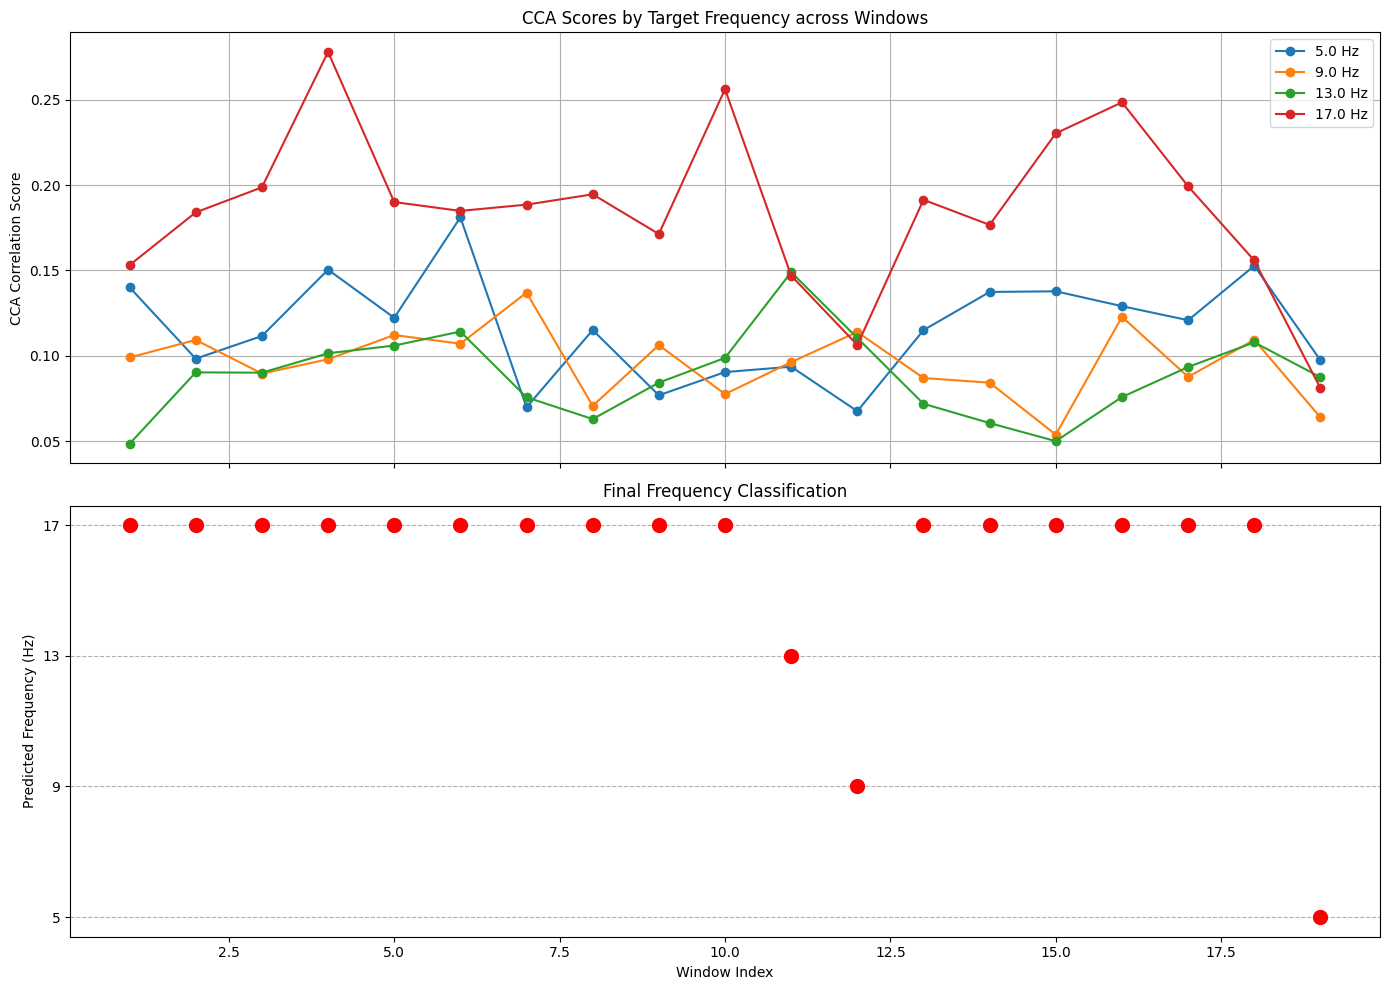

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cross_decomposition import CCA

# 1. Define CCA Parameters
target_freqs = [5.0, 9.0, 13.0, 17.0]
n_harmonics = 2  # Usually 2 to 4 harmonics yield the best accuracy
sr = 200
n_samples = windows[0].shape[0]
t = np.arange(n_samples) / sr

# 2. Generate Reference Signals (Sine/Cosine templates)
def generate_reference_signals(freqs, time_vector, harmonics):
    Y_refs = {}
    for f in freqs:
        y_f = []
        for h in range(1, harmonics + 1):
            y_f.append(np.sin(2 * np.pi * h * f * time_vector))
            y_f.append(np.cos(2 * np.pi * h * f * time_vector))
        Y_refs[f] = np.array(y_f).T  # Shape: (n_samples, 2 * harmonics)
    return Y_refs

Y_ref = generate_reference_signals(target_freqs, t, n_harmonics)

# 3. Apply CCA to each window
predicted_freqs = []
cca_score_matrix = []

# n_components=1 because we only care about the highest correlation pair
cca = CCA(n_components=1)

for window in windows:
    window_scores = []
    
    for f in target_freqs:
        Y = Y_ref[f]
        
        # Fit CCA on the EEG window (X) and the reference signals (Y)
        cca.fit(window, Y)
        X_c, Y_c = cca.transform(window, Y)
        
        # Calculate Pearson correlation of the first canonical variables
        corr = np.corrcoef(X_c[:, 0], Y_c[:, 0])[0, 1]
        window_scores.append(corr)
        
    cca_score_matrix.append(window_scores)
    
    # Classify as the frequency with the maximum correlation score
    best_freq_idx = np.argmax(window_scores)
    predicted_freqs.append(target_freqs[best_freq_idx])

# 4. Plot the CCA Scores and Predicted Frequencies
cca_score_matrix = np.array(cca_score_matrix)
window_indices = np.arange(1, len(windows) + 1)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Top Plot: Line chart of CCA scores for all frequencies over time
for i, f in enumerate(target_freqs):
    ax1.plot(window_indices, cca_score_matrix[:, i], marker='o', label=f'{f} Hz')

ax1.set_ylabel('CCA Correlation Score')
ax1.set_title('CCA Scores by Target Frequency across Windows')
ax1.legend()
ax1.grid(True)

# Bottom Plot: Scatter plot of the final predicted frequency
ax2.scatter(window_indices, predicted_freqs, c='red', s=100, zorder=5)
ax2.set_yticks(target_freqs)
ax2.set_xlabel('Window Index')
ax2.set_ylabel('Predicted Frequency (Hz)')
ax2.set_title('Final Frequency Classification')
ax2.grid(True, axis='y', linestyle='--')

plt.tight_layout()
plt.show()